# 04: Theme Analysis

## 1. Introduction

Theme Analysis is an important stage of the AI-Powered Customer Intelligence and Voice of Customer Analytics Platform.

In this stage, customer reviews are analysed to identify common topics, recurring issues, and important aspects of customer experiences.

While sentiment analysis identifies whether customer feedback is positive, negative, or neutral, theme analysis focuses on understanding what customers are discussing in their reviews.

The analysis uses keyword-based text processing techniques to identify major themes such as product quality, delivery experience, pricing, customer service, packaging, and product performance.

The identified themes will help businesses understand customer concerns, discover improvement opportunities, and make data-driven decisions.

## 2. Importing Libraries and Loading Dataset

The required Python libraries are imported to perform data manipulation, text processing, and theme analysis.

The sentiment analysis results generated in the previous notebook are loaded into the current notebook. This dataset contains cleaned customer reviews along with their sentiment scores and sentiment labels.

The loaded dataset will be used to identify recurring customer feedback themes.

In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Find project root directory

current_path = Path.cwd()
PROJECT_ROOT = None

for path in [current_path, *current_path.parents]:
    if (path / "data").is_dir() and (path / "notebooks").is_dir():
        PROJECT_ROOT = path
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError("Project folder not found.")

# Define processed data directory

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

# Load sentiment analysis results

SENTIMENT_FILE = PROCESSED_DIR / "sentiment_analysis_results.csv"

theme_df = pd.read_csv(SENTIMENT_FILE, low_memory=False)

# Display dataset information

print("Dataset loaded successfully!")
print("Dataset Shape:", theme_df.shape)
print("Total Reviews:", len(theme_df))

display(theme_df.head())

Dataset loaded successfully!
Dataset Shape: (28332, 29)
Total Reviews: 28332


,id,dateAdded,dateUpdated,name,asins,brand,categories,primaryCategories,imageURLs,keys,...,reviews.title,reviews.username,sourceURLs,review_text_clean,review_date,vader_negative,vader_neutral,vader_positive,sentiment_score,sentiment_label
0,AVpgNzjwLJeJML43Kpxn,2015-10-30T08:59:32Z,2019-04-25T09:08:16Z,AmazonBasics AAA Performance Alkaline Batterie...,"B00QWO9P0O,B00LH3DMUO",Amazonbasics,"AA,AAA,Health,Electronics,Health & Household,C...",Health & Beauty,https://images-na.ssl-images-amazon.com/images...,"amazonbasics/hl002619,amazonbasicsaaaperforman...",...,... 3 of them and one of the item is bad quali...,Byger yang,"https://www.barcodable.com/upc/841710106442,ht...",i order 3 of them and one of the item is bad q...,2017-03-02 00:00:00+00:00,0.186,0.814,0.000,-0.6908,Negative
1,AVpgNzjwLJeJML43Kpxn,2015-10-30T08:59:32Z,2019-04-25T09:08:16Z,AmazonBasics AAA Performance Alkaline Batterie...,"B00QWO9P0O,B00LH3DMUO",Amazonbasics,"AA,AAA,Health,Electronics,Health & Household,C...",Health & Beauty,https://images-na.ssl-images-amazon.com/images...,"amazonbasics/hl002619,amazonbasicsaaaperforman...",...,... always the less expensive way to go for pr...,ByMG,"https://www.barcodable.com/upc/841710106442,ht...",bulk is always the less expensive way to go fo...,2016-08-31 00:00:00+00:00,0.000,0.828,0.172,0.3612,Positive
2,AVpgNzjwLJeJML43Kpxn,2015-10-30T08:59:32Z,2019-04-25T09:08:16Z,AmazonBasics AAA Performance Alkaline Batterie...,"B00QWO9P0O,B00LH3DMUO",Amazonbasics,"AA,AAA,Health,Electronics,Health & Household,C...",Health & Beauty,https://images-na.ssl-images-amazon.com/images...,"amazonbasics/hl002619,amazonbasicsaaaperforman...",...,... are not Duracell but for the price i am ha...,BySharon Lambert,"https://www.barcodable.com/upc/841710106442,ht...",well they are not duracell but for the price i...,2016-12-06 00:00:00+00:00,0.000,0.577,0.423,0.7650,Positive
3,AVpgNzjwLJeJML43Kpxn,2015-10-30T08:59:32Z,2019-04-25T09:08:16Z,AmazonBasics AAA Performance Alkaline Batterie...,"B00QWO9P0O,B00LH3DMUO",Amazonbasics,"AA,AAA,Health,Electronics,Health & Household,C...",Health & Beauty,https://images-na.ssl-images-amazon.com/images...,"amazonbasics/hl002619,amazonbasicsaaaperforman...",...,... as well as name brand batteries at a much ...,Bymark sexson,"https://www.barcodable.com/upc/841710106442,ht...",seem to work as well as name brand batteries a...,2016-03-28 00:00:00+00:00,0.000,0.688,0.312,0.6124,Positive
4,AVpgNzjwLJeJML43Kpxn,2015-10-30T08:59:32Z,2019-04-25T09:08:16Z,AmazonBasics AAA Performance Alkaline Batterie...,"B00QWO9P0O,B00LH3DMUO",Amazonbasics,"AA,AAA,Health,Electronics,Health & Household,C...",Health & Beauty,https://images-na.ssl-images-amazon.com/images...,"amazonbasics/hl002619,amazonbasicsaaaperforman...",...,... batteries are very long lasting the price ...,Bylinda,"https://www.barcodable.com/upc/841710106442,ht...",these batteries are very long lasting the pric...,2017-04-22 00:00:00+00:00,0.000,0.687,0.313,0.6249,Positive


## 3. Identifying Required Columns for Theme Analysis

Before performing theme analysis, the important columns required for identifying customer feedback themes are selected from the dataset.

The cleaned review text is used as the primary input for keyword-based theme identification. Sentiment labels and scores are retained to understand the relationship between customer opinions and identified themes.

Product names, categories, and customer ratings are also retained to support further business analysis.

In [2]:
# Select important columns for theme analysis

required_columns = [
    "review_text_clean",
    "sentiment_score",
    "sentiment_label",
    "reviews.rating",
    "name",
    "primaryCategories"
]

theme_analysis_df = theme_df[required_columns].copy()

# Check selected dataset

print("Required columns selected successfully!")
print("Dataset Shape:", theme_analysis_df.shape)

display(theme_analysis_df.head())

# Check missing values
print("\nMissing Values:")
display(theme_analysis_df.isnull().sum())

Required columns selected successfully!
Dataset Shape: (28332, 6)


,review_text_clean,sentiment_score,sentiment_label,reviews.rating,name,primaryCategories
0,i order 3 of them and one of the item is bad q...,-0.6908,Negative,3,AmazonBasics AAA Performance Alkaline Batterie...,Health & Beauty
1,bulk is always the less expensive way to go fo...,0.3612,Positive,4,AmazonBasics AAA Performance Alkaline Batterie...,Health & Beauty
2,well they are not duracell but for the price i...,0.7650,Positive,5,AmazonBasics AAA Performance Alkaline Batterie...,Health & Beauty
3,seem to work as well as name brand batteries a...,0.6124,Positive,5,AmazonBasics AAA Performance Alkaline Batterie...,Health & Beauty
4,these batteries are very long lasting the pric...,0.6249,Positive,5,AmazonBasics AAA Performance Alkaline Batterie...,Health & Beauty



Missing Values:


review_text_clean    0
sentiment_score      0
sentiment_label      0
reviews.rating       0
name                 0
primaryCategories    0
dtype: int64

## 4. Defining Customer Feedback Themes

In this step, predefined customer feedback themes are created using a keyword-based approach.

Each theme represents an important aspect of the customer experience. Relevant keywords are used to identify reviews associated with specific topics.

The following themes are considered:

1. Product Quality: Reviews discussing product quality, defects, durability, and damage.
2. Delivery Experience: Reviews mentioning shipping, delivery time, and delays.
3. Price and Value: Reviews discussing product price, cost, affordability, and value for money.
4. Customer Service: Reviews mentioning customer support, service, and assistance.
5. Product Performance: Reviews discussing product functionality, working condition, and performance.
6. Packaging: Reviews mentioning packaging, boxes, and product wrapping.

A keyword-based approach is used as a baseline method for identifying recurring customer feedback themes.

In [3]:
# Define customer feedback themes and related keywords

theme_keywords = {
    "Product Quality": [
        "quality", "defective", "defect", "broken",
        "damaged", "durable", "durability", "poor quality"
    ],

    "Delivery Experience": [
        "delivery", "delivered", "shipping",
        "shipped", "arrived", "late", "delay"
    ],

    "Price and Value": [
        "price", "cost", "cheap", "expensive",
        "affordable", "value", "money", "worth"
    ],

    "Customer Service": [
        "customer service", "customer support",
        "support", "service", "refund", "replacement"
    ],

    "Product Performance": [
        "works", "working", "performance",
        "function", "effective", "battery life",
        "last long", "stopped working"
    ],

    "Packaging": [
        "packaging", "package", "box",
        "包装", "wrapped", "packing"
    ]
}

print("Customer feedback themes defined successfully!")

for theme, keywords in theme_keywords.items():
    print(f"\n{theme}: {keywords}")

Customer feedback themes defined successfully!

Product Quality: ['quality', 'defective', 'defect', 'broken', 'damaged', 'durable', 'durability', 'poor quality']

Delivery Experience: ['delivery', 'delivered', 'shipping', 'shipped', 'arrived', 'late', 'delay']

Price and Value: ['price', 'cost', 'cheap', 'expensive', 'affordable', 'value', 'money', 'worth']

Customer Service: ['customer service', 'customer support', 'support', 'service', 'refund', 'replacement']

Product Performance: ['works', 'working', 'performance', 'function', 'effective', 'battery life', 'last long', 'stopped working']

Packaging: ['packaging', 'package', 'box', '包装', 'wrapped', 'packing']


## 5. Identifying Themes in Customer Reviews

In this step, the predefined keywords are used to identify relevant themes in customer reviews.

Each review is checked against all six predefined theme categories. A review may belong to more than one theme if it contains keywords related to multiple topics.

The identified themes are stored in a new column named `matched_themes`. Reviews that do not match any predefined theme are classified as "Other".

In [4]:
# Identify matching themes in each customer review

def identify_themes(review):
    review = str(review).lower()
    matched = []

    for theme, keywords in theme_keywords.items():
        for keyword in keywords:
            pattern = r"\b" + re.escape(keyword.lower()) + r"\b"

            if re.search(pattern, review):
                matched.append(theme)
                break

    return matched if matched else ["Other"]


# Apply theme identification to all reviews

theme_analysis_df["matched_themes"] = (
    theme_analysis_df["review_text_clean"].apply(identify_themes)
)

print("Theme identification completed successfully!")

print("\nSample Theme Identification Results:")
display(
    theme_analysis_df[
        ["review_text_clean", "matched_themes"]
    ].head(10)
)

print("\nTotal Reviews:", len(theme_analysis_df))
print(
    "Reviews with at least one identified theme:",
    (theme_analysis_df["matched_themes"].apply(
        lambda themes: themes != ["Other"]
    )).sum()
)

Theme identification completed successfully!

Sample Theme Identification Results:


,review_text_clean,matched_themes
0,i order 3 of them and one of the item is bad q...,[Product Quality]
1,bulk is always the less expensive way to go fo...,[Price and Value]
2,well they are not duracell but for the price i...,[Price and Value]
3,seem to work as well as name brand batteries a...,[Price and Value]
4,these batteries are very long lasting the pric...,[Price and Value]
5,bought a lot of batteries for christmas and th...,[Other]
6,ive not had any problame with these batteries ...,[Other]
7,well if you are looking for cheap non-recharge...,[Price and Value]
8,these do not hold the amount of high power jui...,[Price and Value]
9,amazonbasics aa aaa batteries have done well b...,[Other]



Total Reviews: 28332
Reviews with at least one identified theme: 11480


## 6. Calculating Theme Distribution

In this step, the frequency of each customer feedback theme is calculated.

Since a single review may contain multiple themes, the matched themes are expanded into separate rows before counting.

This analysis helps identify the most frequently discussed topics in customer feedback.

In [5]:
# Calculate the frequency of each customer feedback theme

theme_exploded = theme_analysis_df.explode("matched_themes")

theme_counts = (
    theme_exploded["matched_themes"]
    .value_counts()
    .reset_index()
)

theme_counts.columns = ["Theme", "Review Count"]

print("Customer Feedback Theme Distribution:")
display(theme_counts)

print("\nTotal Theme Mentions:", theme_counts["Review Count"].sum())

Customer Feedback Theme Distribution:


,Theme,Review Count
0,Other,16852
1,Price and Value,7679
2,Product Performance,2926
3,Product Quality,1778
4,Packaging,788
5,Delivery Experience,559
6,Customer Service,429



Total Theme Mentions: 31011


## 7. Visualizing Customer Feedback Theme Distribution

In this step, a horizontal bar chart is created to visualize the frequency of different customer feedback themes.

The visualization helps compare the number of reviews associated with each theme and identify the most frequently discussed customer experience topics.

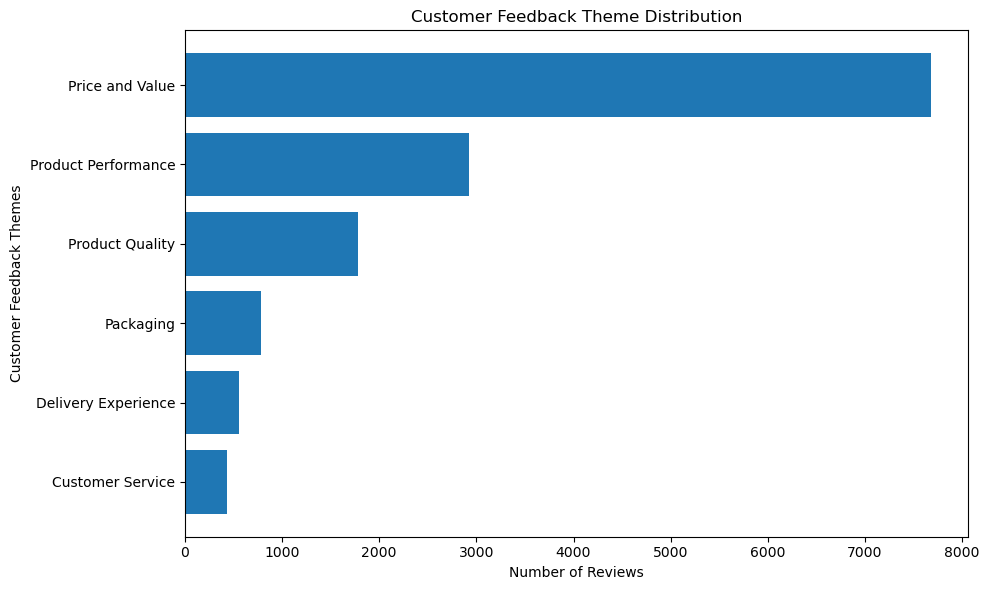

In [6]:
# Visualize customer feedback theme distribution

plot_theme_counts = theme_counts[
    theme_counts["Theme"] != "Other"
].sort_values(by="Review Count", ascending=True)

plt.figure(figsize=(10, 6))

plt.barh(
    plot_theme_counts["Theme"],
    plot_theme_counts["Review Count"]
)

plt.title("Customer Feedback Theme Distribution")
plt.xlabel("Number of Reviews")
plt.ylabel("Customer Feedback Themes")

plt.tight_layout()
plt.show()

## 8. Analyzing Sentiment Across Customer Feedback Themes

In this step, customer sentiment is analyzed across the identified feedback themes.

The number of Positive, Negative, and Neutral reviews is calculated for each theme.

This analysis helps understand which aspects of the customer experience receive negative feedback and which areas are viewed positively by customers.

Reviews classified as "Other" are excluded from this analysis.

In [9]:
# Analyze sentiment distribution across customer feedback themes

# Exclude reviews classified as Other
theme_sentiment_df = theme_exploded[
    theme_exploded["matched_themes"] != "Other"
].copy()

# Reset duplicate index values
theme_sentiment_df = theme_sentiment_df.reset_index(drop=True)

# Calculate theme-wise sentiment distribution
theme_sentiment_counts = pd.crosstab(
    theme_sentiment_df["matched_themes"],
    theme_sentiment_df["sentiment_label"]
)

print("Sentiment Distribution Across Customer Feedback Themes:")
display(theme_sentiment_counts)

print("\nTotal Theme-wise Sentiment Records:",
      theme_sentiment_counts.to_numpy().sum())

Sentiment Distribution Across Customer Feedback Themes:


sentiment_label,Negative,Neutral,Positive
matched_themes,,,
Customer Service,52,12,365
Delivery Experience,52,50,457
Packaging,82,42,664
Price and Value,423,368,6888
Product Performance,233,224,2469
Product Quality,139,76,1563



Total Theme-wise Sentiment Records: 14159


## 9. Visualizing Sentiment Distribution Across Themes

In this step, a stacked bar chart is created to visualize Positive, Negative, and Neutral customer feedback across different themes.

The chart helps compare sentiment patterns across customer experience categories and identify themes that may require business attention.

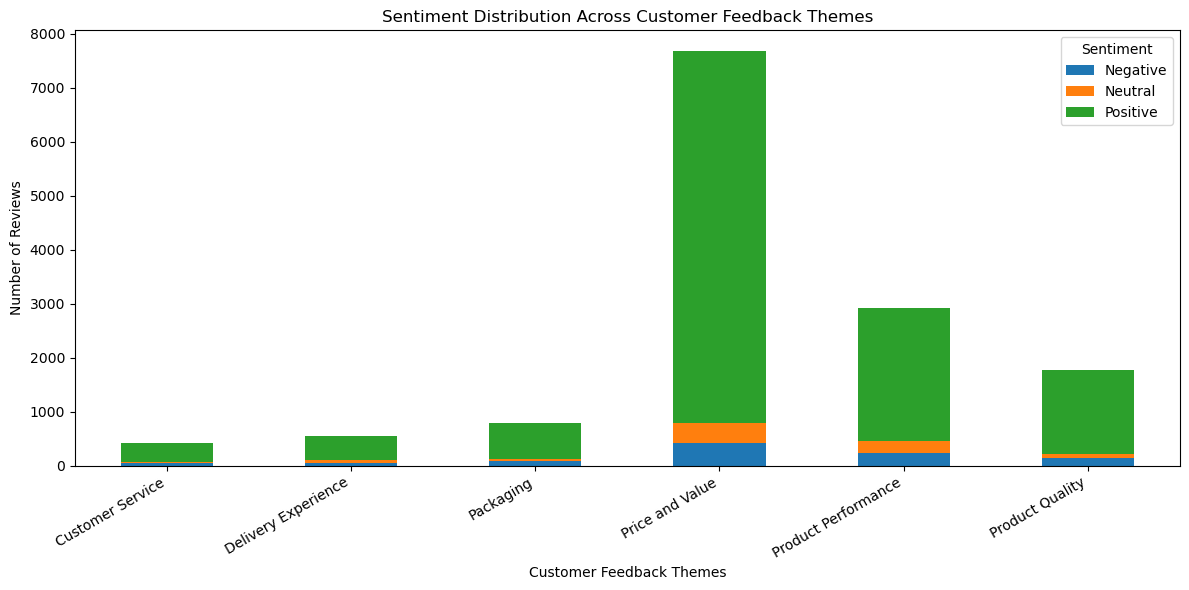

In [10]:
# Visualize sentiment distribution across customer feedback themes

theme_sentiment_counts.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

plt.title("Sentiment Distribution Across Customer Feedback Themes")
plt.xlabel("Customer Feedback Themes")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=30, ha="right")
plt.legend(title="Sentiment")
plt.tight_layout()
plt.show()

## 10. Calculating Negative Sentiment Percentage by Theme

In this step, the percentage of negative feedback is calculated for each customer feedback theme.

Negative sentiment percentage is calculated by dividing the number of negative reviews by the total reviews associated with that theme and multiplying the result by 100.

This analysis provides a fair comparison of negative feedback across themes, regardless of their review volume.

In [11]:
# Calculate negative sentiment percentage for each theme

negative_theme_analysis = pd.DataFrame()

negative_theme_analysis["Total Reviews"] = (
    theme_sentiment_counts.sum(axis=1)
)

negative_theme_analysis["Negative Reviews"] = (
    theme_sentiment_counts["Negative"]
)

negative_theme_analysis["Negative Percentage"] = (
    negative_theme_analysis["Negative Reviews"]
    / negative_theme_analysis["Total Reviews"]
) * 100

negative_theme_analysis = negative_theme_analysis.sort_values(
    by="Negative Percentage",
    ascending=False
)

print("Negative Sentiment Analysis by Theme:")
display(negative_theme_analysis.round(2))

Negative Sentiment Analysis by Theme:


,Total Reviews,Negative Reviews,Negative Percentage
matched_themes,,,
Customer Service,429,52,12.12
Packaging,788,82,10.41
Delivery Experience,559,52,9.30
Product Performance,2926,233,7.96
Product Quality,1778,139,7.82
Price and Value,7679,423,5.51


## 11. Visualizing Negative Sentiment Percentage by Theme

In this step, a horizontal bar chart is created to compare the percentage of negative feedback across different customer feedback themes.

The visualization helps identify customer experience areas with a higher proportion of negative feedback and supports business improvement prioritization.

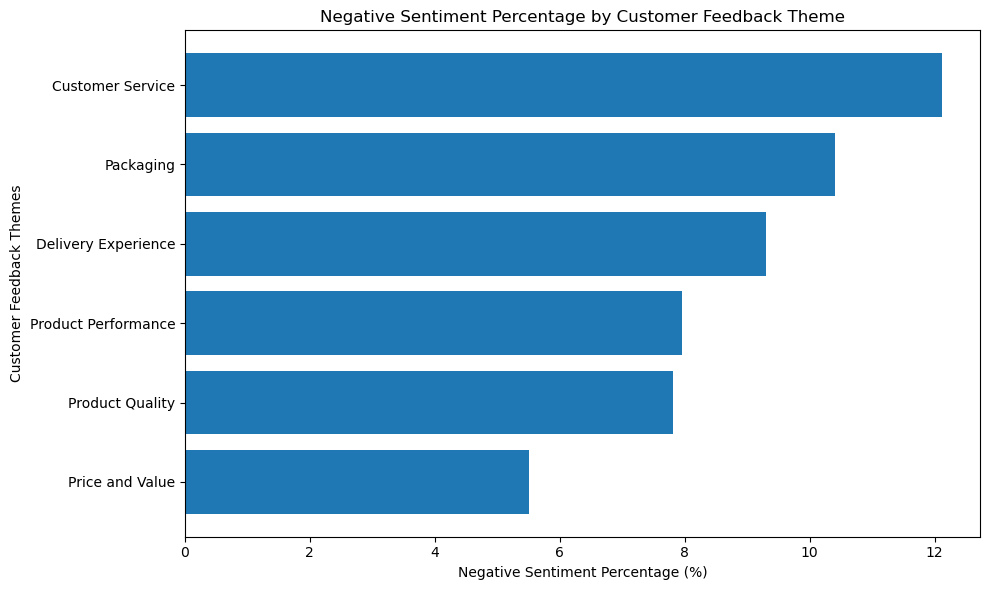

In [12]:
# Visualize negative sentiment percentage by theme

negative_plot = negative_theme_analysis.sort_values(
    by="Negative Percentage",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    negative_plot.index,
    negative_plot["Negative Percentage"]
)

plt.title("Negative Sentiment Percentage by Customer Feedback Theme")
plt.xlabel("Negative Sentiment Percentage (%)")
plt.ylabel("Customer Feedback Themes")

plt.tight_layout()
plt.show()

## 12. Exporting Theme Analysis Results

In this step, the results of theme identification and sentiment analysis are exported into CSV files.

The detailed theme analysis dataset contains customer reviews, sentiment scores, sentiment labels, product information, and identified feedback themes.

Additional CSV files are created for theme distribution and negative sentiment analysis.

These files will be used in the final analysis and business intelligence stages of the project.

In [13]:
# Prepare and export theme analysis results

theme_export_df = theme_analysis_df.copy()

# Convert theme lists into readable text for CSV storage
theme_export_df["matched_themes"] = (
    theme_export_df["matched_themes"].apply(
        lambda themes: "; ".join(themes)
    )
)

# Export detailed theme analysis
theme_export_df.to_csv(
    PROCESSED_DIR / "theme_analysis_results.csv",
    index=False
)

# Export theme distribution
theme_counts.to_csv(
    PROCESSED_DIR / "theme_distribution.csv",
    index=False
)

# Export negative sentiment analysis
negative_theme_analysis.to_csv(
    PROCESSED_DIR / "negative_sentiment_by_theme.csv"
)

print("Theme analysis files exported successfully!")
print("\nExported Files:")
print("1. theme_analysis_results.csv")
print("2. theme_distribution.csv")
print("3. negative_sentiment_by_theme.csv")

Theme analysis files exported successfully!

Exported Files:
1. theme_analysis_results.csv
2. theme_distribution.csv
3. negative_sentiment_by_theme.csv


## 13. Verifying Exported Theme Analysis Files

In this step, all exported theme analysis CSV files are reloaded and verified.

The verification checks whether the files exist, whether their records are correctly stored, and whether the exported datasets retain their expected structure.

This ensures that the theme analysis results are ready for further processing.

In [14]:
# Verify exported theme analysis files

theme_file = PROCESSED_DIR / "theme_analysis_results.csv"
distribution_file = PROCESSED_DIR / "theme_distribution.csv"
negative_file = PROCESSED_DIR / "negative_sentiment_by_theme.csv"

# Reload exported files
verified_theme_df = pd.read_csv(theme_file)
verified_distribution_df = pd.read_csv(distribution_file)
verified_negative_df = pd.read_csv(negative_file)

print("Theme Analysis File Verification")
print("-" * 45)

print("\n1. Theme Analysis Results")
print("File Exists:", theme_file.exists())
print("Shape:", verified_theme_df.shape)

print("\n2. Theme Distribution")
print("File Exists:", distribution_file.exists())
print("Shape:", verified_distribution_df.shape)

print("\n3. Negative Sentiment by Theme")
print("File Exists:", negative_file.exists())
print("Shape:", verified_negative_df.shape)

print("\nAll exported files loaded successfully!")

Theme Analysis File Verification
---------------------------------------------

1. Theme Analysis Results
File Exists: True
Shape: (28332, 7)

2. Theme Distribution
File Exists: True
Shape: (7, 2)

3. Negative Sentiment by Theme
File Exists: True
Shape: (6, 4)

All exported files loaded successfully!


## 14. Business Insights and Interpretation

The theme analysis identified six major customer feedback categories: Product Quality, Delivery Experience, Price and Value, Customer Service, Product Performance, and Packaging.

The analysis produced the following key findings:

1. Price and Value received the highest number of theme mentions, with 7,679 reviews.
2. Product Performance was the second most frequently identified theme, with 2,926 reviews.
3. Customer Service had the highest negative sentiment percentage at 12.12%.
4. Packaging recorded the second-highest negative sentiment percentage at 10.41%.
5. Delivery Experience recorded a negative sentiment percentage of 9.30%.
6. Price and Value had the highest negative review count (423), but its negative sentiment percentage was comparatively low at 5.51%.

These findings indicate that customer service, packaging, and delivery experience deserve attention when prioritizing improvements.

The analysis uses predefined keywords and VADER sentiment classification. Therefore, the identified themes and sentiment labels represent a baseline analysis and may not capture every contextual meaning in customer reviews.

Overall, theme analysis provides useful insights into recurring customer concerns and supports data-driven business decision-making.

In [15]:
# Display final business insights

print("FINAL THEME ANALYSIS SUMMARY")
print("=" * 45)

print("\nTotal Customer Reviews:", len(theme_analysis_df))

print(
    "Reviews with Identified Themes:",
    (theme_analysis_df["matched_themes"].apply(
        lambda themes: themes != ["Other"]
    )).sum()
)

print("\nMost Frequently Discussed Theme:")
print(theme_counts.iloc[1]["Theme"],
      "-", theme_counts.iloc[1]["Review Count"], "mentions")

print("\nTheme with Highest Negative Percentage:")
print(
    negative_theme_analysis.index[0],
    "-",
    round(negative_theme_analysis.iloc[0]["Negative Percentage"], 2),
    "%"
)

print("\nTheme with Highest Negative Review Count:")
print(
    negative_theme_analysis["Negative Reviews"].idxmax(),
    "-",
    negative_theme_analysis["Negative Reviews"].max(),
    "reviews"
)

print("\nNotebook 04 Theme Analysis Completed Successfully!")

FINAL THEME ANALYSIS SUMMARY

Total Customer Reviews: 28332
Reviews with Identified Themes: 11480

Most Frequently Discussed Theme:
Price and Value - 7679 mentions

Theme with Highest Negative Percentage:
Customer Service - 12.12 %

Theme with Highest Negative Review Count:
Price and Value - 423 reviews

Notebook 04 Theme Analysis Completed Successfully!
